In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
import json
import h5py

## Add the path to the DiscEvolution directory
sys.path.append('/Users/ben/Downloads/Planet Formation/Code/DiscEvolution')

## import DiscEvolution modules
from DiscEvolution.chemistry import SimpleCOMolAbund

## Method to Load in Data

In [2]:
## Method to read data from an HDF5 dataset or group

def read_hdf5_array(obj):
    """
    Read data from either an HDF5 dataset or an HDF5 group.
    """

    ## Normal case (the data are stored as one HDF5 dataset)
    if isinstance(obj, h5py.Dataset):
        return np.array(obj)

    ## Ragged case (the data are stored as a group)
    elif isinstance(obj, h5py.Group):
        values = []

        for key in sorted(obj.keys(), key = int):
            values.append(np.array(obj[key]))

        return values

    ## Raise an error if an unexpected HDF5 object is encountered
    else:
        raise TypeError(f"Unexpected HDF5 object type: {type(obj)}")

## Method to load data from an HDF5 file

def load_data(data_dir, config_dir):
    """
    Load a disc evolution output file (HDF5 only).

    Parameters:
        data_dir: Path to the HDF5 output file.
        config_dir: Path to the JSON config file used for the run.

    Returns:
        data: Dictionary containing the simulation output.
        config: Dictionary containing the simulation config file.
    """

    data = {}

    ## Load the configuration file
    with open(config_dir, "r") as f:
        config = json.load(f)

    ## Open the HDF5 file in read-only mode
    with h5py.File(data_dir, "r") as f:

        ## -----------------------
        ## General simulation data
        ## -----------------------

        general_keys = [
            "R",
            "t",
            "disk_Mdot_star",
            "disk_Mass",
            "Tc",
            "Sigc"]

        for key in general_keys:
            ## Only load the quantity if it exists in the file
            if key in f:
                data[key] = np.array(f[key])

        ## -----------------
        ## Scalar attributes
        ## -----------------

        scalar_attributes = [
            "alpha_SS",
            "psi_DW",
            "Mdot",
            "Mdisk",
            "Rd",
            "pla_eff",
            "f_plt",
            "complete",
            "aborted"]

        for key in scalar_attributes:
            ## Only load the attribute if it exists in the file
            if key in f.attrs:
                data[key] = f.attrs[key].item()

        ## Names of the chemical species (only written when chemistry is on)
        if "chem_species" in f.attrs:
            data["chem_species"] = [s.decode() if isinstance(s, bytes) else str(s) for s in f.attrs["chem_species"]]

        ## -------------
        ## Disk profiles
        ## -------------

        disk_keys = [
            "T",
            "time_snap",
            "Sigma_G",
            "Sigma_dust",
            "Sigma_pebbles",
            "Sigma_planetesimals",
            "Vdrift_grains",
            "Vdrift_pebbles",
            "St_grains",
            "St_pebbles",
            "St_planetesimals",
            "e_planetesimals",
            "i_planetesimals",
            "de2_dt",
            "di2_dt",
            "de2_dt_drag",
            "di2_dt_drag",
            "de2_dt_VS_embryo",
            "di2_dt_VS_embryo",
            "de2_dt_VS_pltsml",
            "di2_dt_VS_pltsml",
            "de2_dt_DF",
            "di2_dt_DF",
            "gas_chem",
            "ice_chem",
            "planetesimal_ice_chem"]

        for key in disk_keys:
            ## Only load the quantity if it exists in the file
            if key in f:
                data[key] = read_hdf5_array(f[key])

        ## -----------
        ## Planet data
        ## -----------

        if config["planets"]["include_planets"]:
            planet_keys = [
                "Mcs",
                "Mes",
                "Rp",
                "disk_Mdot_p",
                "Mdot_planetesimal",
                "Mdot_pebble_core",
                "Mdot_pebble_env",
                "Mdot_migration",
                "Mdot_gas",
                "M_iso_planetesimal",
                "M_iso_pebble",
                "X_cores",
                "X_envs",
                "f_env",
                "t_form"]

            for key in planet_keys:
                ## Only load the quantity if it exists in the file
                if key in f:
                    data[key] = read_hdf5_array(f[key])

    return data, config

## Chemistry Functions

In [3]:
## Method to calculate the C/O profile of the disk

def CO_ratio(chem):
    """
    Calculate the C/O ratio from a set of mass abundances.

    Parameters:
        chem: Mass abundances from gas_chem, ice_chem or planetesimal_ice_chem,
              with shape (N_snapshots, N_species, N_radius).

    Returns:
        CO: C/O ratio with shape (N_snapshots, N_radius).
            NaN wherever there is no oxygen.
    """

    n_snap, n_spec, n_R = np.shape(chem)

    CO = np.zeros((n_snap, n_R))

    ## Calculate the profile for each snapshot in turn
    for i in range(n_snap):

        ## Convert the molecular abundances into atomic abundances
        mol = SimpleCOMolAbund(n_R)
        mol.data[:] = chem[i]
        atoms = mol.atomic_abundance()

        with np.errstate(invalid = "ignore", divide = "ignore"):
            CO_i = atoms.number_abund("C") / atoms.number_abund("O")

        CO[i] = np.where(np.isfinite(CO_i), CO_i, np.nan)

    return CO

## Method to calculate the C/H profile of the disk

def CH_ratio(chem):
    """
    Calculate the C/H ratio from a set of mass abundances.
    This is the number of C atoms (in this phase) per hydrogen atom in the gas.

    Parameters:
        chem: Mass abundances from gas_chem, ice_chem or planetesimal_ice_chem,
              with shape (N_snapshots, N_species, N_radius).

    Returns:
        CH: C/H ratio with shape (N_snapshots, N_radius).
    """

    n_snap, n_spec, n_R = np.shape(chem)

    CH = np.zeros((n_snap, n_R))

    ## Calculate the profile for each snapshot in turn
    for i in range(n_snap):

        ## Convert the molecular abundances into atomic abundances
        mol = SimpleCOMolAbund(n_R)
        mol.data[:] = chem[i]
        atoms = mol.atomic_abundance()

        ## Mass per hydrogen atom of the gas
        muH = 1.28

        CH[i] = atoms.number_abund("C") * muH

    return CH

## Method to calculate the O/H profile of the disk

def OH_ratio(chem):
    """
    Calculate the O/H ratio from a set of mass abundances.
    This is the number of O atoms (in this phase) per hydrogen atom in the gas.

    Parameters:
        chem: Mass abundances from gas_chem, ice_chem or planetesimal_ice_chem,
              with shape (N_snapshots, N_species, N_radius).

    Returns:
        OH: O/H ratio with shape (N_snapshots, N_radius).
    """

    n_snap, n_spec, n_R = np.shape(chem)

    OH = np.zeros((n_snap, n_R))

    ## Calculate the profile for each snapshot in turn
    for i in range(n_snap):

        ## Convert the molecular abundances into atomic abundances
        mol = SimpleCOMolAbund(n_R)
        mol.data[:] = chem[i]
        atoms = mol.atomic_abundance()

        ## Mass per hydrogen atom of the gas
        muH = 1.28

        OH[i] = atoms.number_abund("O") * muH

    return OH

## Bulk Composition Functions

In [4]:
## Method to calculate the bulk metallicity profile of the disk

def metallicity(chem):
    """
    Calculate the bulk metallicity from a set of mass abundances.
    This is the mass of heavy elements (in this phase) per unit gas mass, so
    the gas, grains + pebbles, and planetesimal values add up to the total.

    Parameters:
        chem: Mass abundances from gas_chem, ice_chem or planetesimal_ice_chem,
              with shape (N_snapshots, N_species, N_radius).

    Returns:
        Z: Metallicity with shape (N_snapshots, N_radius).
    """

    n_snap, n_spec, n_R = np.shape(chem)

    Z = np.zeros((n_snap, n_R))

    ## Calculate the profile for each snapshot in turn
    for i in range(n_snap):

        ## Load the molecular abundances
        mol = SimpleCOMolAbund(n_R)
        mol.data[:] = chem[i]

        ## Sum over every species
        Z[i] = mol.total_abund

    return Z

## Method to calculate the volatile to refractory ratio profile of the disk

def volatile_refractory_ratio(chem):
    """
    Calculate the volatile to refractory mass ratio from a set of mass abundances.
    Volatiles are CO, CH4, CO2 and H2O and refractories are C-grain and Si-grain.

    Parameters:
        chem: Mass abundances from gas_chem, ice_chem or planetesimal_ice_chem,
              with shape (N_snapshots, N_species, N_radius).

    Returns:
        VR: Volatile to refractory ratio with shape (N_snapshots, N_radius).
            NaN wherever there are no refractories.
    """

    n_snap, n_spec, n_R = np.shape(chem)

    VR = np.zeros((n_snap, n_R))

    ## Calculate the profile for each snapshot in turn
    for i in range(n_snap):

        ## Load the molecular abundances
        mol = SimpleCOMolAbund(n_R)
        mol.data[:] = chem[i]

        volatiles = mol["CO"] + mol["CH4"] + mol["CO2"] + mol["H2O"]
        refractories = mol["C-grain"] + mol["Si-grain"]

        with np.errstate(invalid = "ignore", divide = "ignore"):
            VR_i = volatiles / refractories

        VR[i] = np.where(np.isfinite(VR_i), VR_i, np.nan)

    return VR

## Method to calculate the bulk water content profile of the disk

def water_content(chem):
    """
    Calculate the bulk water content from a set of mass abundances.
    This is the mass fraction of the heavy elements (in this phase) that is H2O.

    Parameters:
        chem: Mass abundances from gas_chem, ice_chem or planetesimal_ice_chem,
              with shape (N_snapshots, N_species, N_radius).

    Returns:
        f_H2O: Water mass fraction with shape (N_snapshots, N_radius).
               NaN wherever there are no heavy elements.
    """

    n_snap, n_spec, n_R = np.shape(chem)

    f_H2O = np.zeros((n_snap, n_R))

    ## Calculate the profile for each snapshot in turn
    for i in range(n_snap):

        ## Load the molecular abundances
        mol = SimpleCOMolAbund(n_R)
        mol.data[:] = chem[i]

        with np.errstate(invalid = "ignore", divide = "ignore"):
            f_H2O_i = mol["H2O"] / mol.total_abund

        f_H2O[i] = np.where(np.isfinite(f_H2O_i), f_H2O_i, np.nan)

    return f_H2O

## Load in Data

In [5]:
## Load data and config file

data_dir = "/Users/ben/Downloads/Planet Formation/DiscEvolution Simulations/Output/popsynth_default_model.h5"
config_dir = "/Users/ben/Downloads/Planet Formation/DiscEvolution Simulations/Config/popsynth_default_config.json"

data, config = load_data(data_dir, config_dir)

In [6]:
## Disc profile
R = data["R"]

## Time data
t = data["t"]
t_interval = config["simulation"]["t_interval"]
n_times = len(t_interval)

# Disk chemistry data
gas_chem = data["gas_chem"]
ice_chem = data["ice_chem"]
planetesimal_ice_chem = data["planetesimal_ice_chem"]

## Global Plotting Style

In [7]:
## Matplotlib colors

color_blues = plt.cm.Blues(np.linspace(1, 0.4, n_times))
color_greys = plt.cm.Greys(np.linspace(1, 0.4, n_times))
color_greens = plt.cm.Greens(np.linspace(1, 0.4, n_times))
color_reds = plt.cm.Reds(np.linspace(1, 0.4, n_times))

## Global plot style

plt.rcParams.update({
    'axes.linewidth': 2.0,
    'axes.labelsize': 14,
    'axes.labelweight': 'normal',
    'xtick.major.width': 2.0,
    'ytick.major.width': 2.0,
    'xtick.minor.width': 1.5,
    'ytick.minor.width': 1.5,
    'xtick.major.size': 6,
    'ytick.major.size': 6,
    'xtick.minor.size': 4,
    'ytick.minor.size': 4,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12})

## Method to bold the tick labels

def bold_ticks(*axes):
    for ax in axes:
        labels = (ax.get_xticklabels() + ax.get_yticklabels()
            + ax.get_xticklabels(minor = True) + ax.get_yticklabels(minor = True))

        for label in labels:
            label.set_fontweight('bold')

## Plot Disk Chemistry Profile

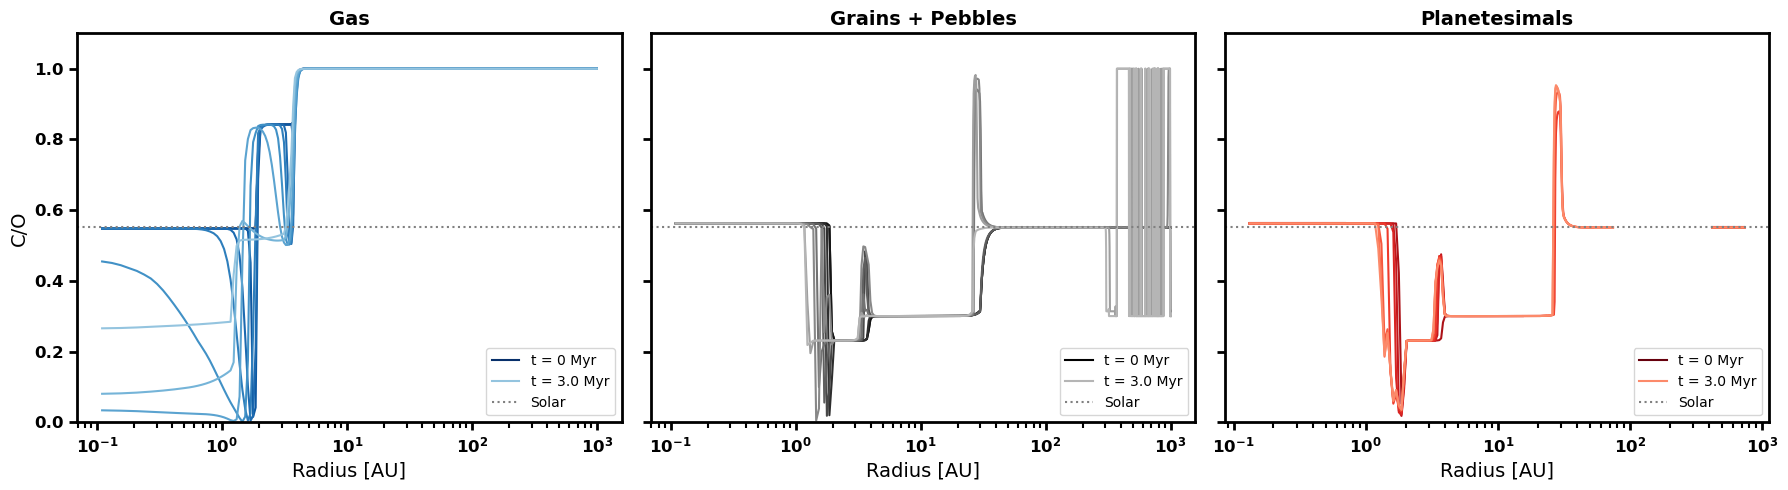

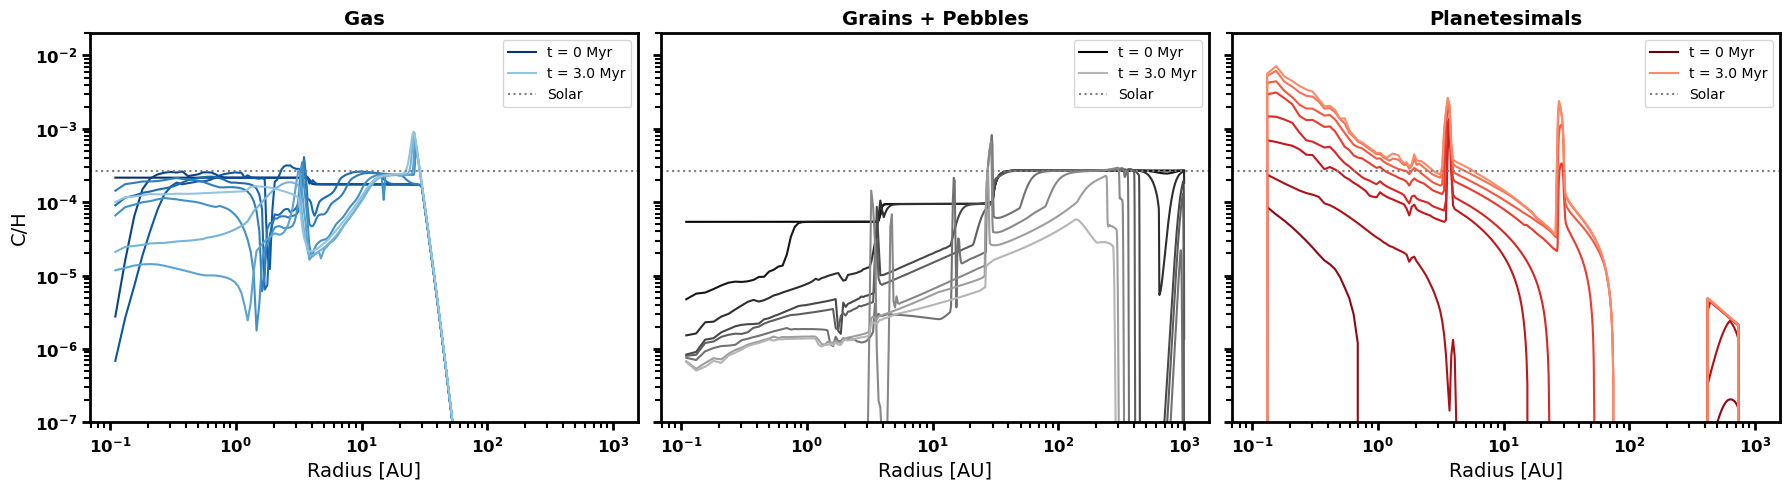

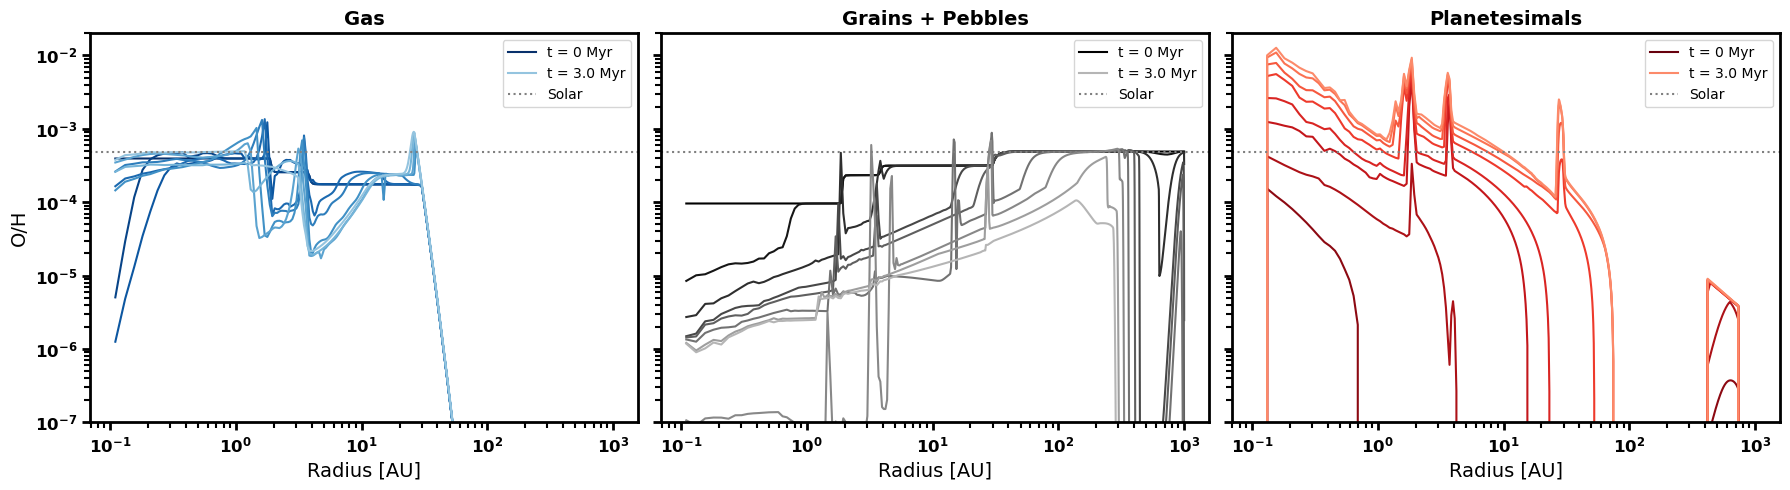

In [8]:
## Chemistry profiles of each phase

phases = {
    "Gas": data["gas_chem"],
    "Grains + Pebbles": data["ice_chem"]}

if config["planetesimal"]["active"]:
    phases["Planetesimals"] = data["planetesimal_ice_chem"]

## Calculate the C/O, C/H and O/H profiles of each phase

ratios = {
    "C/O": [CO_ratio(chem) for chem in phases.values()],
    "C/H": [CH_ratio(chem) for chem in phases.values()],
    "O/H": [OH_ratio(chem) for chem in phases.values()]}

## Solar values used to set the initial abundances

solar = {"C/O": 2.7e-4 / 4.9e-4, "C/H": 2.7e-4, "O/H": 4.9e-4}

## One colour map per phase (gas, grains + pebbles, planetesimals)

phase_colors = [color_blues, color_greys, color_reds]

## y-axis scale, limits and legend position of each ratio

y_scale = {"C/O": 'linear', "C/H": 'log', "O/H": 'log'}
y_lim = {"C/O": (0, 1.1), "C/H": (1e-7, 2e-2), "O/H": (1e-7, 2e-2)}
legend_loc = {"C/O": 'lower right', "C/H": 'upper right', "O/H": 'upper right'}

## One figure per ratio, with a panel for each phase

for ratio in ratios:
    fig, ax = plt.subplots(1, 3, figsize = (6 * 3, 5), sharey = True)

    for j, phase in enumerate(phases):
        for k in range(n_times):
            ## Label first and last timestep
            label = f't = {t_interval[k]} Myr' if k in (0, n_times - 1) else None

            ax[j].plot(R, ratios[ratio][j][k], color = phase_colors[j][k], label = label)

        ## Solar reference value
        ax[j].axhline(solar[ratio], color = '0.5', linestyle = ':', linewidth = 1.5, label = 'Solar')

        ax[j].set_title(phase, fontsize = 14, fontweight = 'bold')

    for j in range(3):
        ax[j].set_xscale('log')
        ax[j].set_yscale(y_scale[ratio])
        ax[j].set_ylim(*y_lim[ratio])
        ax[j].set_xlabel('Radius [AU]')
        ax[j].legend(loc = legend_loc[ratio], fontsize = 10)

    ax[0].set_ylabel(ratio)

    ## Hide the planetesimal panel if planetesimals are switched off
    for j in range(len(phases), 3):
        ax[j].set_visible(False)

    bold_ticks(*ax)

    plt.tight_layout()

    plt.show()

## Plot Disk Bulk Composition Profile

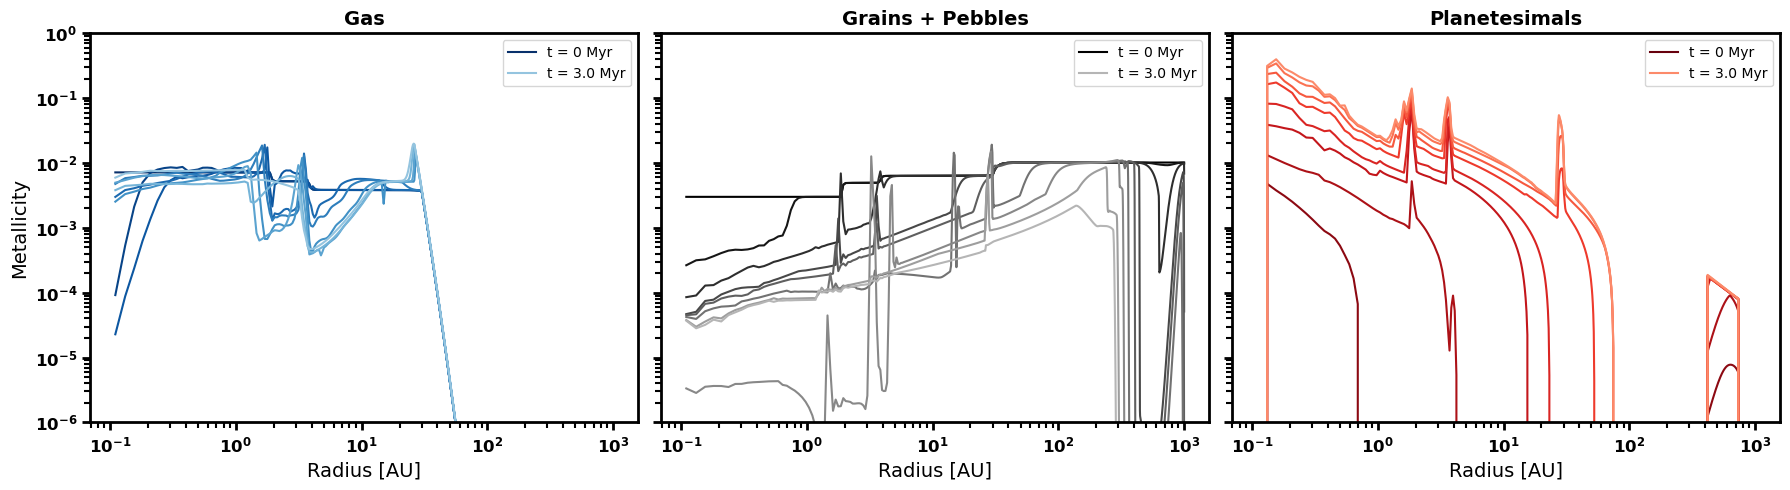

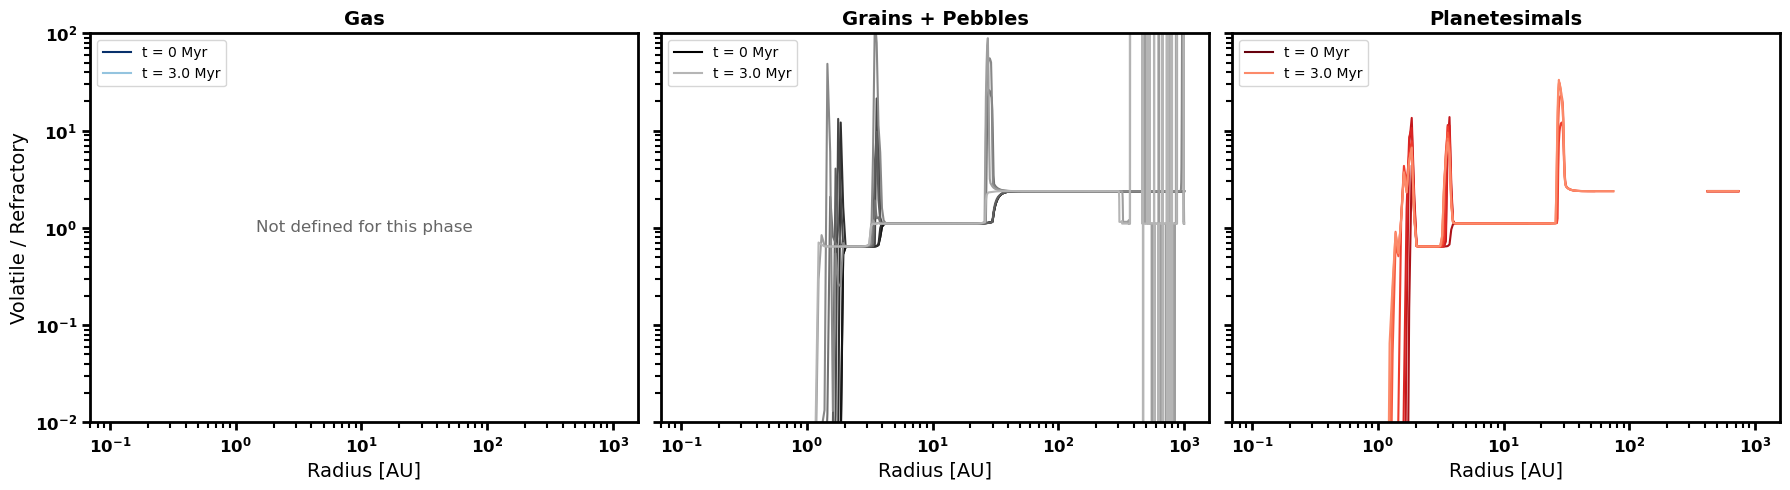

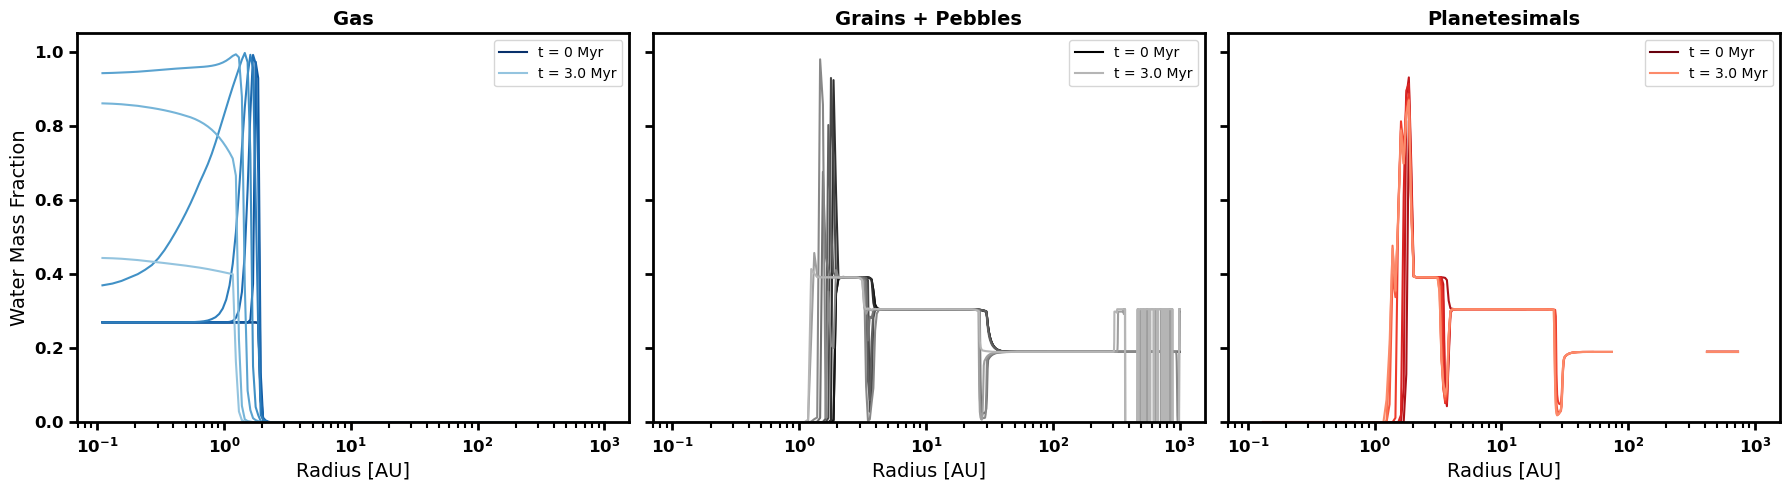

In [9]:
## Bulk composition of each phase

phases = {
    "Gas": data["gas_chem"],
    "Grains + Pebbles": data["ice_chem"]}

if config["planetesimal"]["active"]:
    phases["Planetesimals"] = data["planetesimal_ice_chem"]

## Calculate the metallicity, volatile to refractory ratio and water content of each phase

quantities = {
    "Metallicity": [metallicity(chem) for chem in phases.values()],
    "Volatile / Refractory": [volatile_refractory_ratio(chem) for chem in phases.values()],
    "Water Mass Fraction": [water_content(chem) for chem in phases.values()]}

## One colour map per phase (gas, grains + pebbles, planetesimals)

phase_colors = [color_blues, color_greys, color_reds]

## y-axis scale, limits and legend position of each quantity

y_scale = {"Metallicity": 'log', "Volatile / Refractory": 'log', "Water Mass Fraction": 'linear'}
y_lim = {"Metallicity": (1e-6, 1), "Volatile / Refractory": (1e-2, 1e2), "Water Mass Fraction": (0, 1.05)}
legend_loc = {"Metallicity": 'upper right', "Volatile / Refractory": 'upper left', "Water Mass Fraction": 'upper right'}

## One figure per quantity, with a panel for each phase

for quantity in quantities:
    fig, ax = plt.subplots(1, 3, figsize = (6 * 3, 5), sharex = True, sharey = True)

    for j, phase in enumerate(phases):
        for k in range(n_times):
            ## Label first and last timestep
            label = f't = {t_interval[k]} Myr' if k in (0, n_times - 1) else None

            ax[j].plot(R, quantities[quantity][j][k], color = phase_colors[j][k], label = label)

        ## Note panels with nothing to plot (e.g. there are no refractories in the gas)
        if np.all(np.isnan(quantities[quantity][j])):
            ax[j].text(0.5, 0.5, 'Not defined for this phase', transform = ax[j].transAxes,
                ha = 'center', va = 'center', fontsize = 12, color = '0.4')

        ax[j].set_title(phase, fontsize = 14, fontweight = 'bold')

    for j in range(3):
        ax[j].set_xscale('log')
        ax[j].set_yscale(y_scale[quantity])
        ax[j].set_ylim(*y_lim[quantity])
        ax[j].set_xlabel('Radius [AU]')
        ax[j].legend(loc = legend_loc[quantity], fontsize = 10)

    ax[0].set_ylabel(quantity)

    ## Hide the planetesimal panel if planetesimals are switched off
    for j in range(len(phases), 3):
        ax[j].set_visible(False)

    bold_ticks(*ax)

    plt.tight_layout()

    plt.show()